In [1]:
import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

In [2]:
import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

print("Updated PATH to include MPI")
print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

Updated PATH to include MPI
MPI location: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin
PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



In [3]:
import os
import os.path as op
import numpy as np
import matplotlib.pyplot as plt

import hnn_core

from hnn_core import MPIBackend, JoblibBackend

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/')

from hnn_core import duecker_ET_model, simulate_dipole, jones_2009_model
from hnn_core.externals.mne import tfr_array_morlet
import matplotlib.pyplot as plt
from hnn_core.viz import plot_dipole, plot_psd, plot_tfr_morlet
import numpy as np

from scipy import signal

from alpha_beta_complex import sim_analysis_params_default, run_alpha_beta_complex_simulations, compute_psd, compute_tfr, alpha_beta_ratio


--No graphics will be displayed.


In [4]:
params = sim_analysis_params_default()
params['n_procs'] = 64
params['prox_seed'] = 1+100
params['dist_seed'] = 1+60

In [5]:

dpl, net = run_alpha_beta_complex_simulations(params, n_trials=50)

/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:912: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 50 trial(s) sequentially by distributing network neurons over 64 processes.
numprocs=64
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.soLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so

Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.soLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so

Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/l

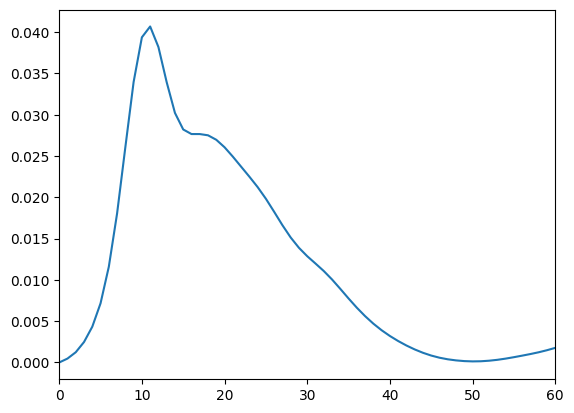

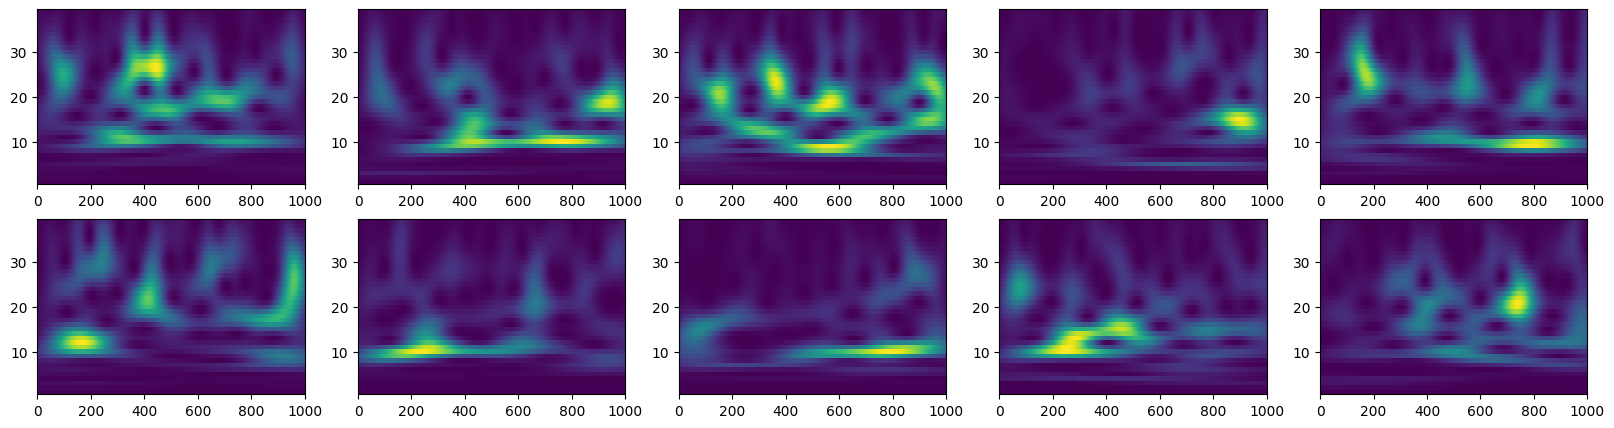

In [10]:
f, psd = compute_psd(params, dpl)
plt.plot(f[0], psd.mean(axis=0))
plt.xlim([0, 60])

tfr = compute_tfr(dpl)

fig, ax = plt.subplots(2,5, figsize=(20,5))
ax = ax.flatten()
for i, a in enumerate(ax):
    a.pcolormesh(dpl[0].times, tfr[0], tfr[1][i], shading='nearest')

In [11]:
ar, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(dpl)

In [12]:
prob_overlap

0.30120481927710846

In [13]:
np.mean(ar), np.median(ar)

(np.float32(1.4955847), np.float32(1.4312953))

/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:912: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 50 trial(s) sequentially by distributing network neurons over 64 processes.
numprocs=64
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.soLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so

Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.soLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so

Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/l

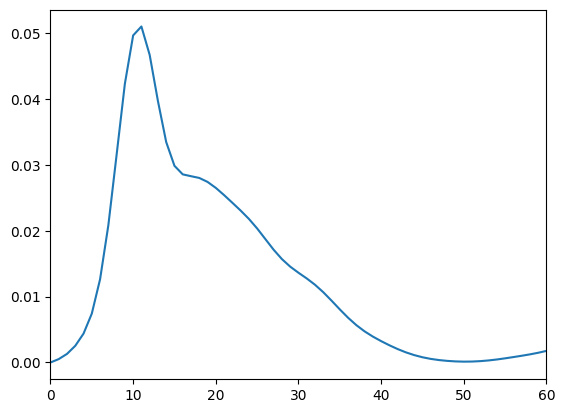

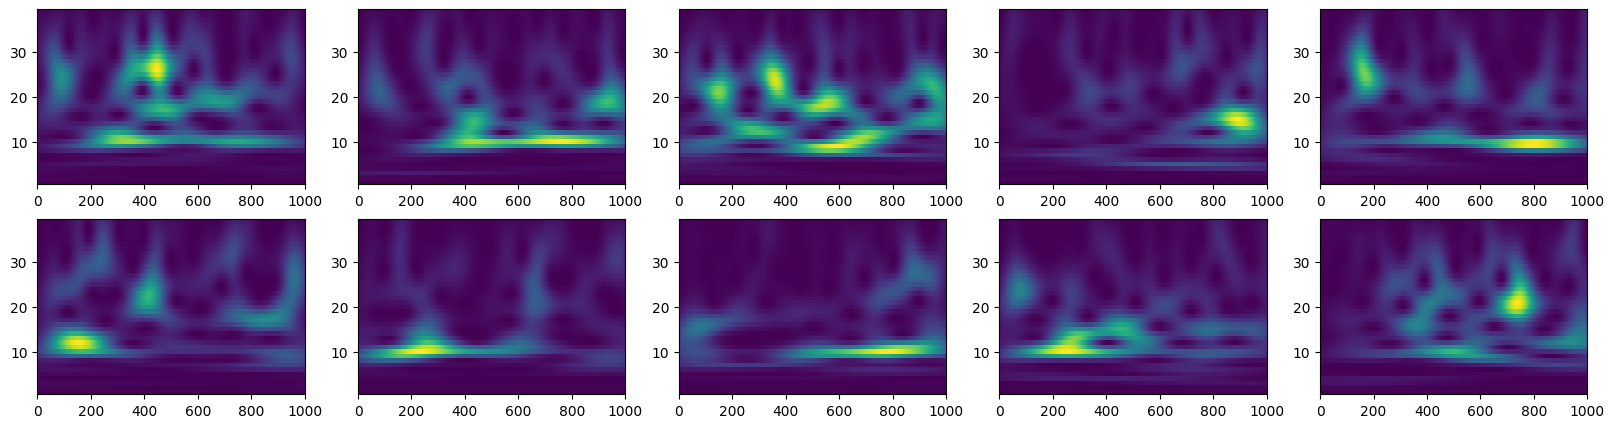

In [14]:
params['fb_delay'] = 0
dpl, net = run_alpha_beta_complex_simulations(params, n_trials=50)

f, psd = compute_psd(params, dpl)
plt.plot(f[0], psd.mean(axis=0))
plt.xlim([0, 60])

tfr = compute_tfr(dpl)

fig, ax = plt.subplots(2,5, figsize=(20,5))
ax = ax.flatten()
for i, a in enumerate(ax):
    a.pcolormesh(dpl[0].times, tfr[0], tfr[1][i], shading='nearest')

In [15]:
ar, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(dpl)

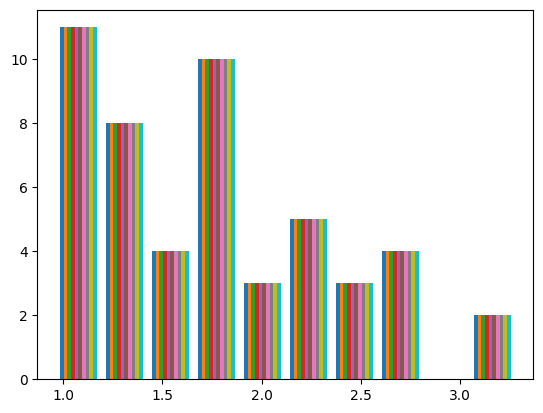

In [16]:
plt.hist(ar);

In [17]:
np.mean(ar), np.median(ar), prob_overlap

(np.float32(1.7656863), np.float32(1.7194438), 0.43373493975903615)

In [ ]:
params['fb_delay'] = 0
params['burst_std_dist'] = 20
dpl, net = run_alpha_beta_complex_simulations(params, n_trials=50)

f, psd = compute_psd(params, dpl)
plt.plot(f[0], psd.mean(axis=0))
plt.xlim([0, 60])

tfr = compute_tfr(dpl)

fig, ax = plt.subplots(2,5, figsize=(20,5))
ax = ax.flatten()
for i, a in enumerate(ax):
    a.pcolormesh(dpl[0].times, tfr[0], tfr[1][i], shading='nearest')

/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:912: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 50 trial(s) sequentially by distributing network neurons over 64 processes.
numprocs=64
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/l

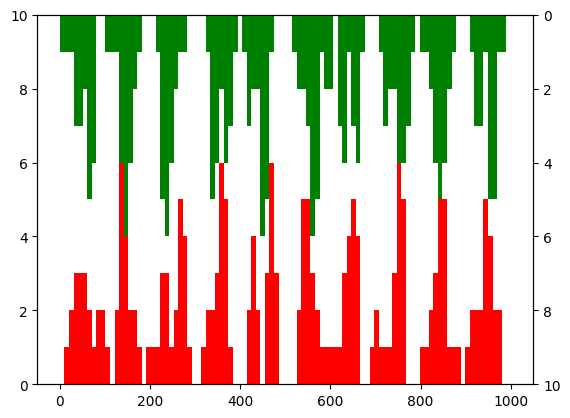

In [29]:
spike_prox = np.array(net.cell_response.spike_times_by_type['prox'][0]).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['dist'][0]).reshape(-1,1)

bins = np.linspace(0, 1000, 100)
fig, ax = plt.subplots()

ax.hist(spike_prox, bins, color='r')
ax.set_ylim([0, 10])
ax1tw = ax.twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 10])
ax1tw.invert_yaxis()

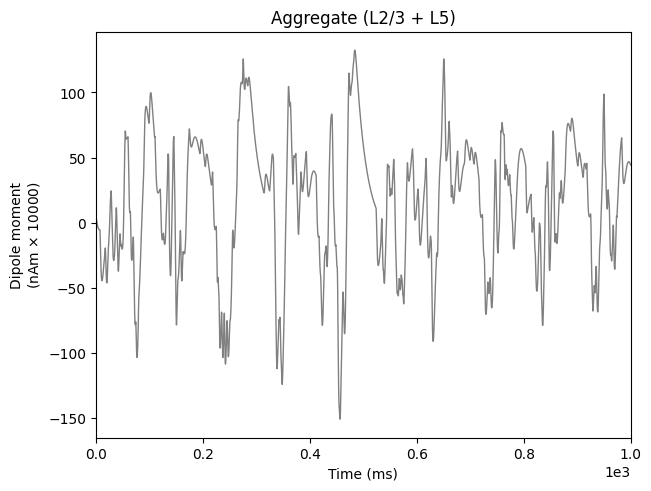

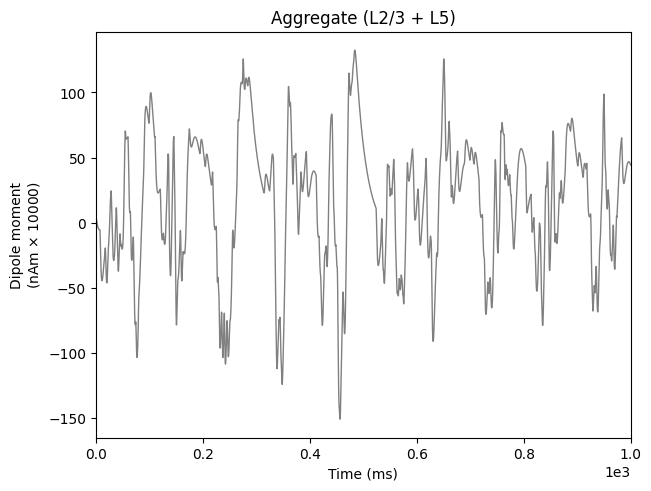

In [20]:
dpl[0].plot()

In [16]:
ar, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(dpl)

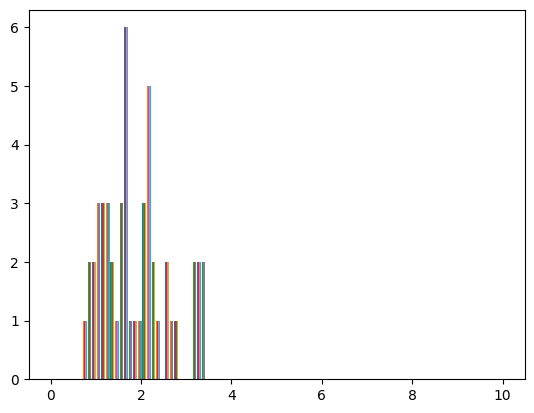

In [17]:
plt.hist(ar, bins=np.linspace(0,10,100));

In [18]:
prob_overlap

0.30120481927710846

In [19]:
np.mean(ar), np.median(ar)

(np.float32(1.8677927), np.float32(1.7144617))